In [5]:
# Older ICU Clinical Twins
from pathlib import Path
import pandas as pd
import numpy as np

data_path = Path.home() / "Downloads"
patients = pd.read_csv(data_path / "patients.csv.gz")
admissions = pd.read_csv(data_path / "admissions.csv.gz")
icustays = pd.read_csv(data_path / "icustays.csv.gz")

print("patients:", patients.shape)
print("admissions:", admissions.shape)
print("icustays:", icustays.shape)

patients: (364627, 6)
admissions: (546028, 16)
icustays: (94458, 8)


In [6]:
# Inspect the columns available in each table

print("PATIENTS")
print(patients.columns.tolist())

print("\nADMISSIONS")
print(admissions.columns.tolist())

print("\nICUSTAYS")
print(icustays.columns.tolist())

PATIENTS
['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']

ADMISSIONS
['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime', 'admission_type', 'admit_provider_id', 'admission_location', 'discharge_location', 'insurance', 'language', 'marital_status', 'race', 'edregtime', 'edouttime', 'hospital_expire_flag']

ICUSTAYS
['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'last_careunit', 'intime', 'outtime', 'los']


In [7]:
# Older adult ICU cohort

# Convert admission and ICU times to datetime
admissions["admittime"] = pd.to_datetime(admissions["admittime"])
icustays["intime"] = pd.to_datetime(icustays["intime"])
icustays["outtime"] = pd.to_datetime(icustays["outtime"])

# Combine ICU stays with hospital admission information
icu_cohort = icustays.merge(admissions,on=["subject_id", "hadm_id"],how="inner")
# Add patient demographic information
icu_cohort = icu_cohort.merge(patients,on="subject_id",how="inner")

print("All ICU stays:", len(icu_cohort))
print("Unique ICU patients:", icu_cohort["subject_id"].nunique())

All ICU stays: 94458
Unique ICU patients: 65366


In [8]:
# Calculate approximate age at the time of hospital admission.
# Age at admission = anchor age + (admission year - anchor year)

icu_cohort["age"] = (icu_cohort["anchor_age"] + (icu_cohort["admittime"].dt.year - icu_cohort["anchor_year"]))
icu_cohort["age"].describe()

count    94458.000000
mean        64.780527
std         16.739041
min         18.000000
25%         55.000000
50%         66.000000
75%         77.000000
max        103.000000
Name: age, dtype: float64

In [9]:
# Define "older adults" as patients age 65 years or older
older_icu = icu_cohort[icu_cohort["age"] >= 65].copy()

print("All ICU stays:", len(icu_cohort))
print("Older adult ICU stays (65+):", len(older_icu))
print("Unique older ICU patients:", older_icu["subject_id"].nunique())
print("Percent of ICU stays involving older adults:",round(len(older_icu) / len(icu_cohort) * 100, 1),"%")

All ICU stays: 94458
Older adult ICU stays (65+): 51730
Unique older ICU patients: 36181
Percent of ICU stays involving older adults: 54.8 %


In [10]:
# Keeping only the first ICU stay for each older adult
older_icu = older_icu.sort_values("intime")
older_icu_first = older_icu.drop_duplicates(subset="subject_id", keep="first").copy()

print("Older adult ICU stays:", len(older_icu))
print("First ICU stay per patient:", len(older_icu_first))
print("Unique patients:", older_icu_first["subject_id"].nunique())

# Age distribution of the final older ICU cohort
print(older_icu_first["age"].describe())

# Confirm that every patient appears only once
print("Duplicate patients:", older_icu_first["subject_id"].duplicated().sum())

Older adult ICU stays: 51730
First ICU stay per patient: 36181
Unique patients: 36181
count    36181.000000
mean        77.002211
std          8.102549
min         65.000000
25%         70.000000
50%         76.000000
75%         83.000000
max        103.000000
Name: age, dtype: float64
Duplicate patients: 0


In [ ]:
# Load diagnosis tables
diagnoses = pd.read_csv(data_path / "diagnoses_icd.csv.gz")
diagnosis_names = pd.read_csv(data_path / "d_icd_diagnoses.csv.gz")

print("Diagnoses table:", diagnoses.shape)
print("Diagnosis names table:", diagnosis_names.shape)
print("\nDiagnoses columns:")
print(diagnoses.columns.tolist())
print("\nDiagnosis names columns:")
print(diagnosis_names.columns.tolist())
print("\nSample diagnoses:")
print(diagnoses.head())
print("\nSample diagnosis names:")
print(diagnosis_names.head())

Diagnoses table: (6364488, 5)
Diagnosis names table: (112107, 3)

Diagnoses columns:
['subject_id', 'hadm_id', 'seq_num', 'icd_code', 'icd_version']

Diagnosis names columns:
['icd_code', 'icd_version', 'long_title']

Sample diagnoses:
   subject_id   hadm_id  seq_num icd_code  icd_version
0    10000032  22595853        1     5723            9
1    10000032  22595853        2    78959            9
2    10000032  22595853        3     5715            9
3    10000032  22595853        4    07070            9
4    10000032  22595853        5      496            9

Sample diagnosis names:
  icd_code  icd_version                             long_title
0     0010            9         Cholera due to vibrio cholerae
1     0011            9  Cholera due to vibrio cholerae el tor
2     0019            9                   Cholera, unspecified
3     0020            9                          Typhoid fever
4     0021            9                    Paratyphoid fever A


In [12]:
# Keeping diagnoses for the selected older ICU cohort
older_diagnoses = diagnoses.merge(older_icu_first[["subject_id", "hadm_id", "stay_id"]],on=["subject_id", "hadm_id"],how="inner")
older_diagnoses = older_diagnoses.merge(diagnosis_names,on=["icd_code", "icd_version"],how="left")

print("Diagnosis records for older ICU cohort:", len(older_diagnoses))
print("Patients with diagnosis records:", older_diagnoses["subject_id"].nunique())
print("Total cohort patients:", len(older_icu_first))
print("Unique ICD codes:", older_diagnoses[["icd_code", "icd_version"]].drop_duplicates().shape[0])
print("\nICD version counts:")
print(older_diagnoses["icd_version"].value_counts())
print("\nDiagnoses per patient:")
print(older_diagnoses.groupby("subject_id").size().describe())
print("\nExample diagnoses:")
print(older_diagnoses[["subject_id", "hadm_id", "seq_num", "icd_code", "icd_version", "long_title"]].head(10))

Diagnosis records for older ICU cohort: 674129
Patients with diagnosis records: 36173
Total cohort patients: 36181
Unique ICD codes: 12594

ICD version counts:
icd_version
10    387138
9     286991
Name: count, dtype: int64

Diagnoses per patient:
count    36173.000000
mean        18.636248
std          8.273993
min          1.000000
25%         12.000000
50%         17.000000
75%         24.000000
max         39.000000
dtype: float64

Example diagnoses:
   subject_id   hadm_id  seq_num icd_code  icd_version  \
0    10000690  25860671        1     5070            9   
1    10000690  25860671        2    42833            9   
2    10000690  25860671        3    51881            9   
3    10000690  25860671        4     5849            9   
4    10000690  25860671        5     5781            9   
5    10000690  25860671        6     2763            9   
6    10000690  25860671        7     5119            9   
7    10000690  25860671        8     5180            9   
8    10000690  2586

In [13]:
# Most common diagnoses among older ICU patients
top_diagnoses = older_diagnoses.groupby(["icd_code", "icd_version", "long_title"])["subject_id"].nunique().reset_index(name="patient_count")
top_diagnoses["patient_percent"] = (top_diagnoses["patient_count"] / len(older_icu_first) * 100).round(1)
top_diagnoses = top_diagnoses.sort_values("patient_count", ascending=False)

print("Top 20 diagnoses among older ICU patients:")
print(top_diagnoses.head(20).to_string(index=False))

Top 20 diagnoses among older ICU patients:
icd_code  icd_version                                                                                                 long_title  patient_count  patient_percent
    E785           10                                                                                Hyperlipidemia, unspecified          10338             28.6
    4019            9                                                                         Unspecified essential hypertension           9005             24.9
     I10           10                                                                           Essential (primary) hypertension           8312             23.0
    2724            9                                                                       Other and unspecified hyperlipidemia           7216             19.9
  Z87891           10                                                                    Personal history of nicotine dependence           7082         

In [14]:
# Checking ICD versions used for each patient's selected admission
patient_icd_versions = older_diagnoses.groupby("subject_id")["icd_version"].nunique()

print("Patients with one ICD version:", (patient_icd_versions == 1).sum())
print("Patients with more than one ICD version:", (patient_icd_versions > 1).sum())
print("\nPrimary ICD version counts:")
print(older_diagnoses.groupby("subject_id")["icd_version"].first().value_counts())

Patients with one ICD version: 36173
Patients with more than one ICD version: 0

Primary ICD version counts:
icd_version
10    18849
9     17324
Name: count, dtype: int64


In [15]:
# Creating major clinical condition groups from diagnosis descriptions
condition_patterns = {
    "hypertension": r"hypertension|hypertensive",
    "diabetes": r"diabetes|diabetic",
    "heart_failure": r"heart failure|cardiac failure",
    "coronary_artery_disease": r"coronary atherosclerosis|atherosclerotic heart disease",
    "atrial_fibrillation": r"atrial fibrillation",
    "chronic_kidney_disease": r"chronic kidney disease|chronic renal failure",
    "acute_kidney_injury": r"acute kidney|acute renal failure",
    "copd": r"chronic obstructive pulmonary|emphysema",
    "respiratory_failure": r"respiratory failure",
    "pneumonia": r"pneumonia",
    "anemia": r"anemia",
    "cancer": r"malignant neoplasm|carcinoma|leukemia|lymphoma",
    "dementia": r"dementia|alzheimer",
    "cerebrovascular_disease": r"cerebral infarction|cerebrovascular|stroke",
    "liver_disease": r"cirrhosis|chronic hepatitis|hepatic failure"
}

# Convert diagnosis descriptions to lowercase for consistent matching
older_diagnoses["diagnosis_text"] = older_diagnoses["long_title"].fillna("").str.lower()

# Count unique patients identified with each condition
condition_counts = []
for condition, pattern in condition_patterns.items():
    patient_count = older_diagnoses.loc[older_diagnoses["diagnosis_text"].str.contains(pattern, regex=True), "subject_id"].nunique()
    condition_counts.append([condition, patient_count, round(patient_count / len(older_icu_first) * 100, 1)])
condition_summary = pd.DataFrame(condition_counts, columns=["condition", "patient_count", "patient_percent"])
condition_summary = condition_summary.sort_values("patient_count", ascending=False)

print(condition_summary.to_string(index=False))

              condition  patient_count  patient_percent
           hypertension          28575             79.0
                 anemia          15921             44.0
    atrial_fibrillation          14320             39.6
coronary_artery_disease          13837             38.2
               diabetes          12290             34.0
    acute_kidney_injury          11823             32.7
                 cancer          11694             32.3
          heart_failure          11571             32.0
    respiratory_failure           9102             25.2
 chronic_kidney_disease           8926             24.7
cerebrovascular_disease           7149             19.8
              pneumonia           6469             17.9
                   copd           3795             10.5
               dementia           3071              8.5
          liver_disease           1950              5.4


In [16]:
# Validating diagnosis titles captured by each clinical condition
for condition, pattern in condition_patterns.items():
    matched = older_diagnoses[older_diagnoses["diagnosis_text"].str.contains(pattern, regex=True)]
    examples = matched.groupby("long_title")["subject_id"].nunique().sort_values(ascending=False).head(5)
    print("\n", condition.upper())
    print(examples)


 HYPERTENSION
long_title
Unspecified essential hypertension                                                                                                9005
Essential (primary) hypertension                                                                                                  8312
Hypertensive chronic kidney disease, unspecified, with chronic kidney disease stage I through stage IV, or unspecified            2891
Hypertensive heart disease with heart failure                                                                                     2294
Hypertensive chronic kidney disease with stage 1 through stage 4 chronic kidney disease, or unspecified chronic kidney disease    2045
Name: subject_id, dtype: int64

 DIABETES
long_title
Diabetes mellitus without mention of complication, type II or unspecified type, not stated as uncontrolled    3964
Type 2 diabetes mellitus without complications                                                                2302
Type 2 diabetes 

In [17]:
# Refining cancer and cerebrovascular disease to exclude personal history diagnoses
condition_patterns["cancer"] = r"malignant neoplasm|carcinoma|leukemia|lymphoma"
condition_patterns["cerebrovascular_disease"] = r"cerebral infarction|cerebrovascular|stroke"

# Creating a flag for diagnoses describing personal history
older_diagnoses["personal_history"] = older_diagnoses["diagnosis_text"].str.contains("personal history", regex=False)

# Recalculating condition counts after refinement
condition_counts = []
for condition, pattern in condition_patterns.items():
    matched = older_diagnoses["diagnosis_text"].str.contains(pattern, regex=True)
    if condition in ["cancer", "cerebrovascular_disease"]:
        matched = matched & ~older_diagnoses["personal_history"]
    patient_count = older_diagnoses.loc[matched, "subject_id"].nunique()
    condition_counts.append([condition, patient_count, round(patient_count / len(older_icu_first) * 100, 1)])

condition_summary = pd.DataFrame(condition_counts, columns=["condition", "patient_count", "patient_percent"])
condition_summary = condition_summary.sort_values("patient_count", ascending=False)
print(condition_summary.to_string(index=False))

              condition  patient_count  patient_percent
           hypertension          28575             79.0
                 anemia          15921             44.0
    atrial_fibrillation          14320             39.6
coronary_artery_disease          13837             38.2
               diabetes          12290             34.0
    acute_kidney_injury          11823             32.7
          heart_failure          11571             32.0
    respiratory_failure           9102             25.2
 chronic_kidney_disease           8926             24.7
              pneumonia           6469             17.9
                 cancer           5913             16.3
cerebrovascular_disease           4538             12.5
                   copd           3795             10.5
               dementia           3071              8.5
          liver_disease           1950              5.4


In [18]:
# Creating binary clinical condition features for each patient
patient_conditions = older_icu_first[["subject_id"]].copy()

for condition, pattern in condition_patterns.items():
    matched = older_diagnoses["diagnosis_text"].str.contains(pattern, regex=True)
    if condition in ["cancer", "cerebrovascular_disease"]:
        matched = matched & ~older_diagnoses["personal_history"]
    patients_with_condition = older_diagnoses.loc[matched, "subject_id"].unique()
    patient_conditions[condition] = patient_conditions["subject_id"].isin(patients_with_condition).astype(int)

print("Patient-condition matrix:", patient_conditions.shape)
print("Unique patients:", patient_conditions["subject_id"].nunique())
print("\nFirst 10 patients:")
print(patient_conditions.head(10).to_string(index=False))
print("\nNumber of conditions per patient:")
print(patient_conditions.drop(columns="subject_id").sum(axis=1).describe())

Patient-condition matrix: (36181, 16)
Unique patients: 36181

First 10 patients:
 subject_id  hypertension  diabetes  heart_failure  coronary_artery_disease  atrial_fibrillation  chronic_kidney_disease  acute_kidney_injury  copd  respiratory_failure  pneumonia  anemia  cancer  dementia  cerebrovascular_disease  liver_disease
   15463892             1         0              0                        1                    1                       1                    0     0                    0          0       1       1         0                        0              0
   18780420             1         0              0                        0                    1                       0                    0     0                    0          0       1       0         0                        1              0
   10525750             1         1              0                        1                    0                       1                    1     0                    0          0  

In [19]:
# Checking patients not represented by any of the 15 selected conditions
condition_total = patient_conditions.drop(columns="subject_id").sum(axis=1)
zero_condition_patients = patient_conditions[condition_total == 0]

print("Patients with zero selected conditions:", len(zero_condition_patients))
print("Percent of cohort:", round(len(zero_condition_patients) / len(patient_conditions) * 100, 1), "%")

Patients with zero selected conditions: 764
Percent of cohort: 2.1 %


In [20]:
# Creating the final Clinical Twins dataset
clinical_twins = older_icu_first[["subject_id", "stay_id", "hadm_id", "age", "gender", "los", "hospital_expire_flag"]].merge(patient_conditions,on="subject_id",how="inner")
condition_columns = list(condition_patterns.keys())
clinical_twins["condition_count"] = clinical_twins[condition_columns].sum(axis=1)

# Excluding patients with none of the selected clinical conditions
clinical_twins = clinical_twins[clinical_twins["condition_count"] > 0].copy()

# Converting gender to a numeric ML feature
clinical_twins["gender_female"] = (clinical_twins["gender"] == "F").astype(int)

print("Final Clinical Twins cohort:", len(clinical_twins))
print("Unique patients:", clinical_twins["subject_id"].nunique())
print("Mean age:", round(clinical_twins["age"].mean(), 1))
print("Female patients:", clinical_twins["gender_female"].sum())
print("Hospital deaths:", clinical_twins["hospital_expire_flag"].sum())
print("Median ICU LOS:", round(clinical_twins["los"].median(), 2), "days")

Final Clinical Twins cohort: 35417
Unique patients: 35417
Mean age: 77.1
Female patients: 16324
Hospital deaths: 4885
Median ICU LOS: 1.99 days


In [21]:
# Preparing features for the Clinical Twins model
from sklearn.preprocessing import StandardScaler

feature_columns = ["age", "gender_female"] + condition_columns
X = clinical_twins[feature_columns].copy()

# Standardizing features so different numerical scales do not dominate similarity
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Number of patients:", X.shape[0])
print("Number of ML features:", X.shape[1])
print("Features used:")
print(feature_columns)
print("\nOriginal age mean:", round(X["age"].mean(), 2))
print("Scaled age mean:", round(X_scaled[:, 0].mean(), 2))
print("Scaled age standard deviation:", round(X_scaled[:, 0].std(), 2))

Number of patients: 35417
Number of ML features: 17
Features used:
['age', 'gender_female', 'hypertension', 'diabetes', 'heart_failure', 'coronary_artery_disease', 'atrial_fibrillation', 'chronic_kidney_disease', 'acute_kidney_injury', 'copd', 'respiratory_failure', 'pneumonia', 'anemia', 'cancer', 'dementia', 'cerebrovascular_disease', 'liver_disease']

Original age mean: 77.07
Scaled age mean: -0.0
Scaled age standard deviation: 1.0


In [22]:
# Building the Nearest Neighbors model
from sklearn.neighbors import NearestNeighbors

nn_model = NearestNeighbors(n_neighbors=6, metric="euclidean")
nn_model.fit(X_scaled)

# Finding the 6 nearest neighbors for every patient
distances, indices = nn_model.kneighbors(X_scaled)

print("Model fitted successfully")
print("Distance matrix shape:", distances.shape)
print("Neighbor index matrix shape:", indices.shape)
print("First patient's distances:", distances[0])
print("First patient's neighbor indices:", indices[0])

Model fitted successfully
Distance matrix shape: (35417, 6)
Neighbor index matrix shape: (35417, 6)
First patient's distances: [0.         0.49382934 0.98765868 2.02127866 2.03765151 2.07003446]
First patient's neighbor indices: [    0 13360  2996 31982 32696 18433]


In [23]:
# Checking similarity to each patient's closest Clinical Twin
closest_twin_distance = distances[:, 1]

print("Closest-twin distance distribution:")
print(pd.Series(closest_twin_distance).describe())
print("Patients with an exact twin:", (closest_twin_distance == 0).sum())

Closest-twin distance distribution:
count    3.541700e+04
mean     4.573296e-01
std      7.789331e-01
min      0.000000e+00
25%      5.960464e-08
50%      1.234573e-01
75%      4.938293e-01
max      5.367690e+00
dtype: float64
Patients with an exact twin: 7336


In [24]:
# Displaying one patient and their five closest Clinical Twins
target_index = 0
twin_indices = indices[target_index, 1:6]
twin_distances = distances[target_index, 1:6]

target = clinical_twins.iloc[[target_index]].copy()
twins = clinical_twins.iloc[twin_indices].copy()

comparison = pd.concat([target, twins], ignore_index=True)
comparison["patient"] = ["Target"] + ["Twin 1", "Twin 2", "Twin 3", "Twin 4", "Twin 5"]
comparison["distance"] = [0] + list(twin_distances)

display_columns = ["patient", "age", "gender", "distance"] + condition_columns + ["los", "hospital_expire_flag"]
print(comparison[display_columns].to_string(index=False))

patient  age gender  distance  hypertension  diabetes  heart_failure  coronary_artery_disease  atrial_fibrillation  chronic_kidney_disease  acute_kidney_injury  copd  respiratory_failure  pneumonia  anemia  cancer  dementia  cerebrovascular_disease  liver_disease      los  hospital_expire_flag
 Target   83      M  0.000000             1         0              0                        1                    1                       1                    0     0                    0          0       1       1         0                        0              0 4.980428                     0
 Twin 1   79      M  0.493829             1         0              0                        1                    1                       1                    0     0                    0          0       1       1         0                        0              0 4.154421                     0
 Twin 2   91      M  0.987659             1         0              0                        1                    1 

In [26]:
# Comparing ICU LOS differences for Clinical Twins versus random patient pairs
np.random.seed(42)

closest_twin_indices = indices[:, 1]
patient_los = clinical_twins["los"].to_numpy()
twin_los = clinical_twins.iloc[closest_twin_indices]["los"].to_numpy()

random_indices = np.random.permutation(len(clinical_twins))
random_los = clinical_twins.iloc[random_indices]["los"].to_numpy()

twin_los_difference = np.abs(patient_los - twin_los)
random_los_difference = np.abs(patient_los - random_los)

print("Missing LOS values:", clinical_twins["los"].isna().sum())
print("Median LOS difference - Clinical Twins:", round(np.nanmedian(twin_los_difference), 2), "days")
print("Median LOS difference - Random pairs:", round(np.nanmedian(random_los_difference), 2), "days")
print("Mean LOS difference - Clinical Twins:", round(np.nanmean(twin_los_difference), 2), "days")
print("Mean LOS difference - Random pairs:", round(np.nanmean(random_los_difference), 2), "days")

Missing LOS values: 6
Median LOS difference - Clinical Twins: 1.18 days
Median LOS difference - Random pairs: 1.69 days
Mean LOS difference - Clinical Twins: 2.86 days
Mean LOS difference - Random pairs: 3.63 days


In [27]:
# Comparing mortality agreement for Clinical Twins versus random patient pairs
patient_mortality = clinical_twins["hospital_expire_flag"].to_numpy()
twin_mortality = clinical_twins.iloc[closest_twin_indices]["hospital_expire_flag"].to_numpy()
random_mortality = clinical_twins.iloc[random_indices]["hospital_expire_flag"].to_numpy()

twin_mortality_agreement = (patient_mortality == twin_mortality).mean() * 100
random_mortality_agreement = (patient_mortality == random_mortality).mean() * 100

print("Mortality agreement - Clinical Twins:", round(twin_mortality_agreement, 1), "%")
print("Mortality agreement - Random pairs:", round(random_mortality_agreement, 1), "%")

Mortality agreement - Clinical Twins: 82.4 %
Mortality agreement - Random pairs: 76.3 %


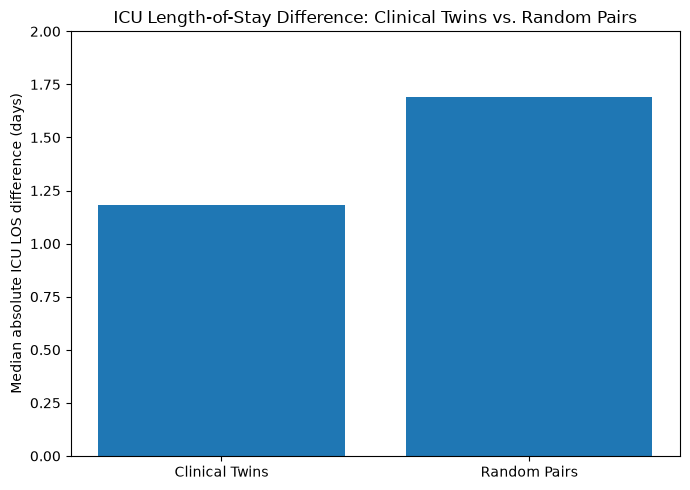

In [35]:
# Visualizing ICU LOS similarity for Clinical Twins versus random pairs
import matplotlib.pyplot as plt

labels = ["Clinical Twins", "Random Pairs"]
median_los = [np.nanmedian(twin_los_difference), np.nanmedian(random_los_difference)]

plt.figure(figsize=(7, 5))
plt.bar(labels, median_los)
plt.ylabel("Median absolute ICU LOS difference (days)")
plt.ylim(0, 2)
plt.title("ICU Length-of-Stay Difference: Clinical Twins vs. Random Pairs")
plt.tight_layout()
plt.show()

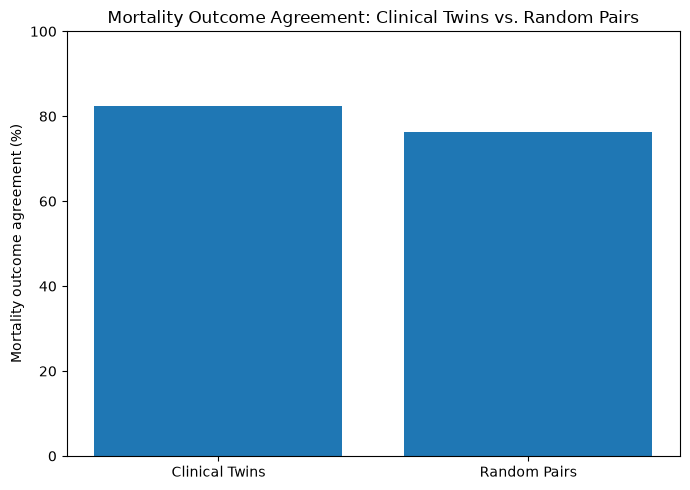

In [34]:
# Visualizing mortality agreement for Clinical Twins versus random pairs
labels = ["Clinical Twins", "Random Pairs"]
mortality_agreement = [twin_mortality_agreement, random_mortality_agreement]

plt.figure(figsize=(7, 5))
plt.bar(labels, mortality_agreement)
plt.ylabel("Mortality outcome agreement (%)")
plt.ylim(0, 100)
plt.title("Mortality Outcome Agreement: Clinical Twins vs. Random Pairs")
plt.tight_layout()
plt.show()

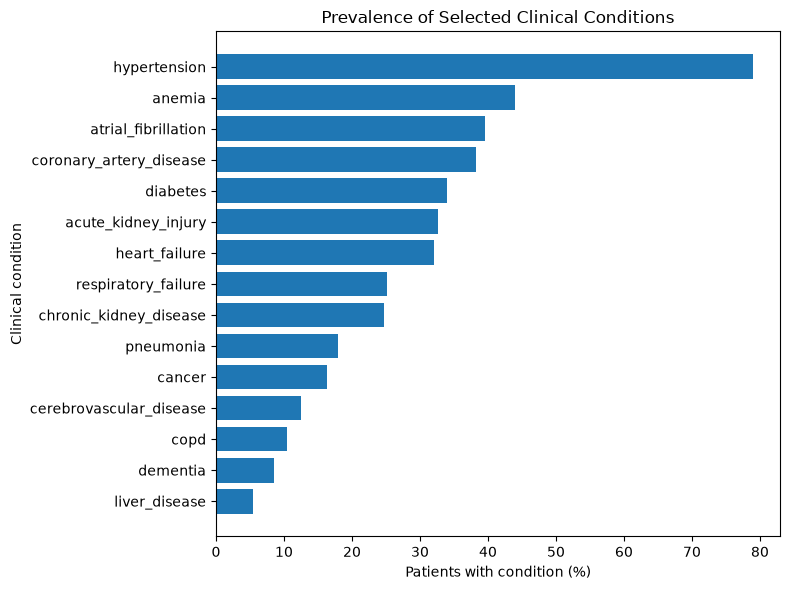

In [33]:
# Visualizing the clinical conditions used to define Clinical Twins
plot_data = condition_summary.sort_values("patient_percent")

plt.figure(figsize=(8, 6))
plt.barh(plot_data["condition"], plot_data["patient_percent"])
plt.xlabel("Patients with condition (%)")
plt.ylabel("Clinical condition")
plt.title("Prevalence of Selected Clinical Conditions")
plt.tight_layout()
plt.show()

In [36]:
# Calculating improvement in outcome similarity
los_improvement = (np.nanmedian(random_los_difference) - np.nanmedian(twin_los_difference)) / np.nanmedian(random_los_difference) * 100
mortality_improvement = twin_mortality_agreement - random_mortality_agreement

print("Reduction in median ICU LOS difference:", round(los_improvement, 1), "%")
print("Increase in mortality agreement:", round(mortality_improvement, 1), "percentage points")

Reduction in median ICU LOS difference: 30.1 %
Increase in mortality agreement: 6.2 percentage points
